# COMP9444 Group Project

## Disease Named Entity Recognition using Pre-trained Language Models

### 1. Introduction

Disease Named Entity Recognition (NER) is an important task in biomedical natural language processing. It aims to identify disease mentions in biomedical text, such as scientific articles and medical documents.

In this project, we investigate the performance of three pre-trained language models on the NCBI Disease dataset:

- BERT
- BioBERT
- PubMedBERT

The objective is to compare the performance of general-domain and biomedical-domain pre-trained language models on disease entity recognition.

We evaluate the models using precision, recall, F1-score, and accuracy. We also analyse their prediction errors to better understand the strengths and limitations of each model.

## 2. Environment Setup

We use Python, PyTorch, and Hugging Face Transformers to implement and evaluate the three baseline models.

A fixed random seed is used to improve the reproducibility of our experiments.

In [1]:
import os

os.environ["USE_TF"] = "0"
os.environ["USE_TORCH"] = "1"

import sys
import random
import numpy as np
import pandas as pd
import torch

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)

Python version: 3.11.17 (main, Oct  1 2026, 20:09:52) [Clang 20.1.8 ]
PyTorch version: 2.15.0


In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Random seed:", SEED)
print("Device:", device)

Random seed: 42
Device: mps


## 3. Dataset

We use the NCBI Disease dataset for disease named entity recognition.

The dataset contains biomedical text annotated with disease mentions. Each sentence consists of a sequence of tokens and their corresponding NER labels.

The dataset is divided into three subsets:

- Training set: used to train the models.
- Validation set: used to evaluate model performance during training.
- Test set: used to evaluate the final performance of each model.

The dataset uses the BIO tagging scheme:

- B-Disease: the beginning of a disease entity.
- I-Disease: a token inside a disease entity.
- O: a token that does not belong to any disease entity.

In [3]:
from datasets import load_dataset

dataset = load_dataset("ncbi/ncbi_disease")

print(dataset)

/opt/anaconda3/envs/neuralnet/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 5433
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 924
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 941
    })
})


In [4]:
print("Training samples:", len(dataset["train"]))
print("Validation samples:", len(dataset["validation"]))
print("Test samples:", len(dataset["test"]))

print("\nExample from the training set:")
print(dataset["train"][0])

Training samples: 5433
Validation samples: 924
Test samples: 941

Example from the training set:
{'id': '0', 'tokens': ['Identification', 'of', 'APC2', ',', 'a', 'homologue', 'of', 'the', 'adenomatous', 'polyposis', 'coli', 'tumour', 'suppressor', '.'], 'ner_tags': [0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 2, 2, 0, 0]}


### 3.1 Exploratory Data Analysis

We examine the distribution of BIO labels and sentence lengths in the NCBI Disease dataset.

The label distribution helps us understand the class imbalance between disease and non-disease tokens. Sentence length analysis provides information about the input sequences and helps identify potential tokenization and truncation challenges.

In [37]:
from collections import Counter

dataset_label_names = dataset["train"].features["ner_tags"].feature.names

label_counts = {}

for split in ["train", "validation", "test"]:

    counts = Counter()

    for sample in dataset[split]:
        for tag in sample["ner_tags"]:
            counts[dataset_label_names[tag]] += 1

    label_counts[split] = counts

label_distribution_df = pd.DataFrame(label_counts)

display(label_distribution_df)

,train,validation,test
O,124819,22092,22450
B-Disease,5145,787,960
I-Disease,6122,1090,1087


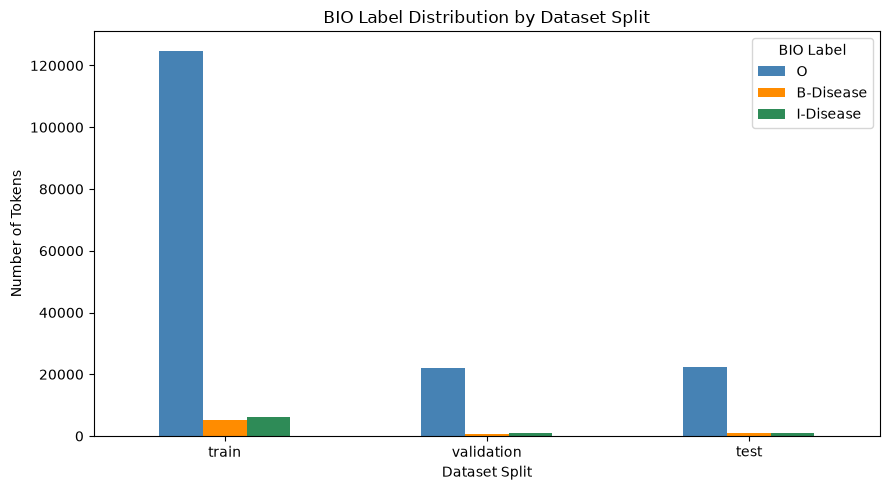

In [38]:
import matplotlib.pyplot as plt

label_distribution_df.T.plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "darkorange", "seagreen"]
)

plt.title("BIO Label Distribution by Dataset Split")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Tokens")
plt.xticks(rotation=0)
plt.legend(title="BIO Label")

plt.tight_layout()
plt.show()

,train,validation,test
Mean,25.05,25.97,26.06
Median,23.00,24.00,24.00
Maximum,123.00,86.00,106.00


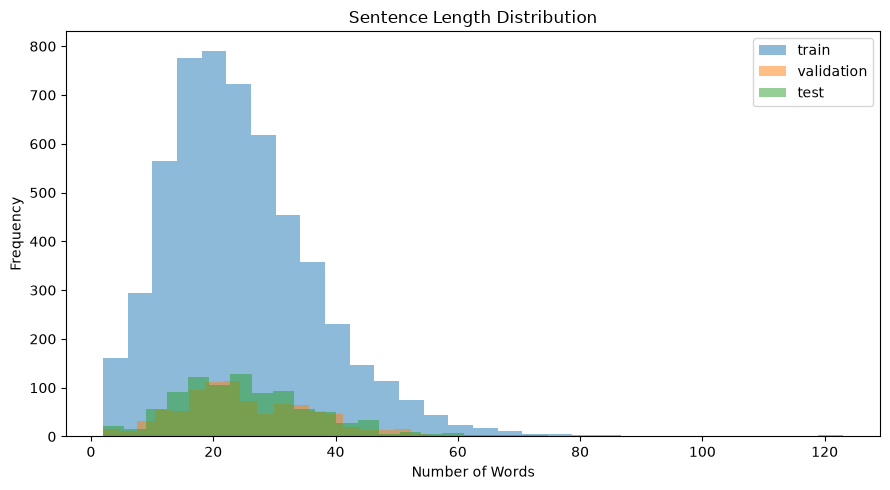

In [39]:
sentence_lengths = {}

for split in ["train", "validation", "test"]:

    sentence_lengths[split] = [
        len(sample["tokens"])
        for sample in dataset[split]
        if len(sample["tokens"]) > 0
    ]

length_summary = pd.DataFrame({
    split: {
        "Mean": np.mean(lengths),
        "Median": np.median(lengths),
        "Maximum": np.max(lengths)
    }
    for split, lengths in sentence_lengths.items()
})

display(length_summary.round(2))

plt.figure(figsize=(9, 5))

for split, lengths in sentence_lengths.items():
    plt.hist(
        lengths,
        bins=30,
        alpha=0.5,
        label=split
    )

plt.title("Sentence Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()
plt.show()

### 3.2 Exploratory Analysis Findings

The BIO label distribution shows a clear class imbalance across all three dataset splits.

In the training set, approximately 91.7% of tokens are labelled O, while disease-related tokens account for only 8.3%. This imbalance explains why token-level accuracy alone may not provide a reliable measure of disease recognition performance. Therefore, we use entity-level F1-score as the primary evaluation metric.

The sentence length analysis shows similar distributions across the three dataset splits. The average sentence length ranges from approximately 25 to 26 words, with median lengths of 23 to 24 words.

The longest sentence contains 123 words in the training set. Although the original sentences are relatively short, subword tokenization may increase their lengths. We therefore consider the maximum input length when preparing data for the pre-trained models.

## 4. Data Audit

Before training the models, we conduct a data audit to verify the consistency of the NCBI Disease dataset.

We compare the Hugging Face dataset with the CoNLL TSV files for the training, validation, and test splits.

The audit checks sentence counts, token sequences, BIO labels, missing rows, and invalid BIO transitions. This helps ensure that the models are evaluated using consistent and reliable data.

In [5]:
"""Compare an already loaded Hugging Face NCBI Disease dataset with CoNLL TSVs."""

from collections import Counter
from hashlib import sha256
from itertools import zip_longest
from pathlib import Path
from urllib.request import urlopen


CONLL_URL = "https://raw.githubusercontent.com/spyysalo/ncbi-disease/master/conll/"
SPLIT_FILES = {"train": "train.tsv", "validation": "devel.tsv", "test": "test.tsv"}
LABEL_NAMES = ("O", "B-Disease", "I-Disease")


def read_conll(raw):
    rows = []
    tokens, tags = [], []
    for line_number, line in enumerate(raw.decode("utf-8").splitlines(), start=1):
        if not line.strip():
            if tokens:
                rows.append((tokens, tags))
                tokens, tags = [], []
            continue

        token, separator, tag = line.partition("\t")
        tag = tag.rstrip()
        if not separator or not token or tag not in LABEL_NAMES:
            raise ValueError(f"Invalid CoNLL row on line {line_number}: {line!r}")
        tokens.append(token)
        tags.append(tag)

    if tokens:
        rows.append((tokens, tags))
    return rows


def audit_ncbi_splits(hf_dataset, conll_dir=None):
    """Print split statistics and return True when all ordered rows match."""
    all_match = True
    for split, filename in SPLIT_FILES.items():
        if conll_dir is None:
            with urlopen(CONLL_URL + filename, timeout=60) as response:
                raw = response.read()
        else:
            raw = (Path(conll_dir) / filename).read_bytes()

        conll_rows = read_conll(raw)
        hf_rows = hf_dataset[split]
        hf_labels = hf_rows.features["ner_tags"].feature
        token_mismatches = label_mismatches = missing_rows = invalid_bio = 0
        tag_counts = Counter()
        first_difference = None

        for row_number, (hf_row, conll_row) in enumerate(zip_longest(hf_rows, conll_rows)):
            hf_value = None
            if hf_row is not None:
                tokens = hf_row["tokens"]
                tags = [hf_labels.int2str(tag) for tag in hf_row["ner_tags"]]
                if len(tokens) != len(tags) or not set(tags).issubset(LABEL_NAMES):
                    raise ValueError(f"Invalid Hugging Face row: {split}[{row_number}]")
                hf_value = (tokens, tags)
                tag_counts.update(tags)
                previous = "O"
                for tag in tags:
                    invalid_bio += tag == "I-Disease" and previous == "O"
                    previous = tag

            if hf_value is None or conll_row is None:
                missing_rows += 1
            else:
                token_mismatches += hf_value[0] != conll_row[0]
                label_mismatches += hf_value[1] != conll_row[1]
            if hf_value != conll_row and first_difference is None:
                first_difference = (row_number, hf_value, conll_row)

        matches = first_difference is None
        all_match &= matches
        print(f"\n{split}: {'EXACT MATCH' if matches else 'DIFFERENT'}")
        print(f"  Sentences: Hugging Face={len(hf_rows)}, CoNLL={len(conll_rows)}")
        print(f"  Rows with different tokens: {token_mismatches}")
        print(f"  Rows with different BIO labels: {label_mismatches}")
        print(f"  Rows present in only one source: {missing_rows}")
        print(f"  Hugging Face BIO counts: {dict(tag_counts)}")
        print(f"  Annotated disease starts (B-Disease): {tag_counts['B-Disease']}")
        print(f"  Orphan I-Disease tags: {invalid_bio}")
        print(f"  CoNLL SHA-256: {sha256(raw).hexdigest()}")
        if not matches:
            row_number, hf_value, conll_row = first_difference
            print(f"  First difference at zero-based row {row_number}:")
            print(f"    Hugging Face: {hf_value!r}\n    CoNLL: {conll_row!r}")

    return all_match

In [6]:
audit_result = audit_ncbi_splits(dataset)

print("\nAll dataset splits match:", audit_result)


train: DIFFERENT
  Sentences: Hugging Face=5433, CoNLL=5432
  Rows with different tokens: 0
  Rows with different BIO labels: 0
  Rows present in only one source: 1
  Hugging Face BIO counts: {'O': 124819, 'B-Disease': 5145, 'I-Disease': 6122}
  Annotated disease starts (B-Disease): 5145
  Orphan I-Disease tags: 0
  CoNLL SHA-256: 5f87b0de649eccff21e6d6e49e304aace808056ecae55225ea31602192517be9
  First difference at zero-based row 5432:
    Hugging Face: ([], [])
    CoNLL: None

validation: DIFFERENT
  Sentences: Hugging Face=924, CoNLL=923
  Rows with different tokens: 0
  Rows with different BIO labels: 0
  Rows present in only one source: 1
  Hugging Face BIO counts: {'O': 22092, 'B-Disease': 787, 'I-Disease': 1090}
  Annotated disease starts (B-Disease): 787
  Orphan I-Disease tags: 0
  CoNLL SHA-256: b4e1e7efcc2a35047bf2f3d281648357470e674f555d4a26a0049ac37d59cc61
  First difference at zero-based row 923:
    Hugging Face: ([], [])
    CoNLL: None

test: DIFFERENT
  Sentences: H

### 4.1 Data Cleaning

The data audit identifies empty samples in the Hugging Face dataset that are not present in the CoNLL version.

These empty samples contain no tokens or NER labels and provide no useful information for model training or evaluation.

We remove empty samples from each dataset split before tokenization.

In [7]:
for split in ["train", "validation", "test"]:
    empty_count = 0

    for sample in dataset[split]:
        if len(sample["tokens"]) == 0:
            empty_count += 1

    print(split, "empty samples:", empty_count)

train empty samples: 1
validation empty samples: 1
test empty samples: 1


In [8]:
clean_dataset = dataset.filter(
    lambda sample: len(sample["tokens"]) > 0
)

print("Dataset after cleaning:")

for split in ["train", "validation", "test"]:
    print(split, len(clean_dataset[split]))

Dataset after cleaning:
train 5432
validation 923
test 940


In [9]:
clean_audit_result = audit_ncbi_splits(clean_dataset)

print("\nAll cleaned dataset splits match:", clean_audit_result)


train: EXACT MATCH
  Sentences: Hugging Face=5432, CoNLL=5432
  Rows with different tokens: 0
  Rows with different BIO labels: 0
  Rows present in only one source: 0
  Hugging Face BIO counts: {'O': 124819, 'B-Disease': 5145, 'I-Disease': 6122}
  Annotated disease starts (B-Disease): 5145
  Orphan I-Disease tags: 0
  CoNLL SHA-256: 5f87b0de649eccff21e6d6e49e304aace808056ecae55225ea31602192517be9

validation: EXACT MATCH
  Sentences: Hugging Face=923, CoNLL=923
  Rows with different tokens: 0
  Rows with different BIO labels: 0
  Rows present in only one source: 0
  Hugging Face BIO counts: {'O': 22092, 'B-Disease': 787, 'I-Disease': 1090}
  Annotated disease starts (B-Disease): 787
  Orphan I-Disease tags: 0
  CoNLL SHA-256: b4e1e7efcc2a35047bf2f3d281648357470e674f555d4a26a0049ac37d59cc61

test: EXACT MATCH
  Sentences: Hugging Face=940, CoNLL=940
  Rows with different tokens: 0
  Rows with different BIO labels: 0
  Rows present in only one source: 0
  Hugging Face BIO counts: {'O': 

## 5. Data Preprocessing

Before training the models, we preprocess the cleaned NCBI Disease dataset.

The preprocessing includes:

- Extracting the BIO label mappings.
- Tokenizing sentences using the tokenizer of each pre-trained model.
- Aligning NER labels with subword tokens.
- Preparing the tokenized datasets for model training and evaluation.

Since BERT, BioBERT, and PubMedBERT may use different tokenizers, we apply the corresponding tokenizer to each model.

In [10]:
label_names = clean_dataset["train"].features["ner_tags"].feature.names

num_labels = len(label_names)

id2label = {
    i: label for i, label in enumerate(label_names)
}

label2id = {
    label: i for i, label in enumerate(label_names)
}

print("Label names:", label_names)
print("Number of labels:", num_labels)
print("ID to label:", id2label)
print("Label to ID:", label2id)

Label names: ['O', 'B-Disease', 'I-Disease']
Number of labels: 3
ID to label: {0: 'O', 1: 'B-Disease', 2: 'I-Disease'}
Label to ID: {'O': 0, 'B-Disease': 1, 'I-Disease': 2}


In [11]:
example = clean_dataset["train"][0]

example_df = pd.DataFrame({
    "Token": example["tokens"],
    "Label": [id2label[tag] for tag in example["ner_tags"]]
})

display(example_df)

,Token,Label
0,Identification,O
1,of,O
2,APC2,O
3,",",O
4,a,O
5,homologue,O
6,of,O
7,the,O
8,adenomatous,B-Disease
9,polyposis,I-Disease


### 5.1 Tokenization and Label Alignment

The pre-trained models use subword tokenization, which may split a word into multiple tokens.

To align the original BIO labels with the tokenized input, we assign the original label to the first subword of each word. Special tokens and subsequent subwords are assigned a label of -100, which is ignored during loss calculation and evaluation.

This alignment strategy is used consistently across the three baseline models.

In [12]:
def tokenize_and_align_labels(examples, tokenizer):
    tokenized_inputs = tokenizer(
        examples["tokens"],
        truncation=True,
        is_split_into_words=True
    )

    all_labels = []

    for i, labels in enumerate(examples["ner_tags"]):
        word_ids = tokenized_inputs.word_ids(batch_index=i)

        label_ids = []
        previous_word_id = None

        for word_id in word_ids:
            if word_id is None:
                label_ids.append(-100)

            elif word_id != previous_word_id:
                label_ids.append(labels[word_id])

            else:
                label_ids.append(-100)

            previous_word_id = word_id

        all_labels.append(label_ids)

    tokenized_inputs["labels"] = all_labels

    return tokenized_inputs

In [13]:
from transformers import AutoTokenizer

bert_tokenizer = AutoTokenizer.from_pretrained(
    "bert-base-cased"
)

print("BERT tokenizer loaded successfully.")

BERT tokenizer loaded successfully.


In [14]:
biobert_tokenizer = AutoTokenizer.from_pretrained(
    "bert-base-cased"
)

pubmedbert_tokenizer = AutoTokenizer.from_pretrained(
    "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract"
)

print("All tokenizers loaded successfully.")

All tokenizers loaded successfully.


In [15]:
bert_dataset = clean_dataset.map(
    lambda examples: tokenize_and_align_labels(
        examples, bert_tokenizer
    ),
    batched=True,
    remove_columns=clean_dataset["train"].column_names
)

biobert_dataset = clean_dataset.map(
    lambda examples: tokenize_and_align_labels(
        examples, biobert_tokenizer
    ),
    batched=True,
    remove_columns=clean_dataset["train"].column_names
)

pubmedbert_dataset = clean_dataset.map(
    lambda examples: tokenize_and_align_labels(
        examples, pubmedbert_tokenizer
    ),
    batched=True,
    remove_columns=clean_dataset["train"].column_names
)

print("All datasets tokenized successfully.")

All datasets tokenized successfully.


In [16]:
print("BERT:")
print(bert_dataset)

print("\nBioBERT:")
print(biobert_dataset)

print("\nPubMedBERT:")
print(pubmedbert_dataset)

BERT:
DatasetDict({
    train: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 5432
    })
    validation: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 923
    })
    test: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 940
    })
})

BioBERT:
DatasetDict({
    train: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 5432
    })
    validation: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 923
    })
    test: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 940
    })
})

PubMedBERT:
DatasetDict({
    train: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 5432
    })
    valid

In [17]:
sample = pubmedbert_dataset["train"][0]

tokens = pubmedbert_tokenizer.convert_ids_to_tokens(
    sample["input_ids"]
)

labels = [
    id2label[tag] if tag != -100 else "Ignored"
    for tag in sample["labels"]
]

alignment_df = pd.DataFrame({
    "Token": tokens,
    "Label": labels
})

display(alignment_df)

,Token,Label
0,[CLS],Ignored
1,identification,O
2,of,O
3,apc,O
4,##2,Ignored
5,",",O
6,a,O
7,homologue,O
8,of,O
9,the,O


## 6. Evaluation Metrics

We evaluate the models using four metrics:

- Precision: the proportion of predicted disease entities that are correct.
- Recall: the proportion of actual disease entities that are correctly identified.
- F1-score: the harmonic mean of precision and recall.
- Accuracy: the proportion of correctly predicted token labels.

Precision, recall, and F1-score are calculated at the entity level using the seqeval library. Accuracy is calculated at the token level.

We use F1-score as the primary evaluation metric because it balances precision and recall and is more informative for disease entity recognition than token-level accuracy alone.

In [18]:
from seqeval.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

In [19]:
def compute_metrics(eval_pred):
    predictions, labels = eval_pred

    predictions = np.argmax(predictions, axis=-1)

    true_predictions = []
    true_labels = []

    for prediction, label in zip(predictions, labels):
        sentence_predictions = []
        sentence_labels = []

        for p, l in zip(prediction, label):
            if l != -100:
                sentence_predictions.append(id2label[p])
                sentence_labels.append(id2label[l])

        true_predictions.append(sentence_predictions)
        true_labels.append(sentence_labels)

    return {
        "precision": precision_score(
            true_labels, true_predictions
        ),
        "recall": recall_score(
            true_labels, true_predictions
        ),
        "f1": f1_score(
            true_labels, true_predictions
        ),
        "accuracy": accuracy_score(
            true_labels, true_predictions
        )
    }

## 7. BERT Baseline

BERT is used as the general-domain baseline in this project.

We fine-tune the pre-trained `bert-base-cased` model on the NCBI Disease dataset for token classification. The model predicts one of three BIO labels for each word.

BERT provides a reference for evaluating whether biomedical-domain pre-training improves disease named entity recognition.

### 7.1 Experimental Configuration

The original BERT experiment uses the following hyperparameters:

| Hyperparameter | Value |
|---|---|
| Pre-trained model | bert-base-cased |
| Learning rate | 2e-5 |
| Training epochs | 3 |
| Training batch size | 8 |
| Evaluation batch size | 8 |
| Weight decay | 0.01 |
| Evaluation strategy | Every epoch |
| Maximum sequence length | 512 |

In [20]:
bert_config = {
    "model_name": "bert-base-cased",
    "learning_rate": 2e-5,
    "num_train_epochs": 3,
    "train_batch_size": 8,
    "eval_batch_size": 8,
    "weight_decay": 0.01,
    "max_length": 512
}

display(pd.DataFrame(
    bert_config.items(),
    columns=["Hyperparameter", "Value"]
))

,Hyperparameter,Value
0,model_name,bert-base-cased
1,learning_rate,0.00002
2,num_train_epochs,3
3,train_batch_size,8
4,eval_batch_size,8
5,weight_decay,0.01
6,max_length,512


### 7.2 Model Training

The BERT model is fine-tuned using a token classification head with three output labels.

We use the training set to update the model parameters and the validation set to evaluate performance after each epoch.

Dynamic padding is applied using DataCollatorForTokenClassification. Tokens with a label of -100 are ignored during loss calculation.

The trained model is evaluated on the test set using the evaluation metrics defined in Section 6.

In [40]:
def train_bert():

    from transformers import (
        AutoModelForTokenClassification,
        DataCollatorForTokenClassification,
        TrainingArguments,
        Trainer
    )

    bert_model = AutoModelForTokenClassification.from_pretrained(
        bert_config["model_name"],
        num_labels=num_labels,
        id2label=id2label,
        label2id=label2id
    )

    bert_data_collator = DataCollatorForTokenClassification(
        tokenizer=bert_tokenizer
    )

    bert_training_args = TrainingArguments(
        output_dir="./bert-ner-baseline",
        learning_rate=bert_config["learning_rate"],
        per_device_train_batch_size=bert_config["train_batch_size"],
        per_device_eval_batch_size=bert_config["eval_batch_size"],
        num_train_epochs=bert_config["num_train_epochs"],
        weight_decay=bert_config["weight_decay"],
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_steps=50,
        report_to="none"
    )

    bert_trainer = Trainer(
        model=bert_model,
        args=bert_training_args,
        train_dataset=bert_dataset["train"],
        eval_dataset=bert_dataset["validation"],
        processing_class=bert_tokenizer,
        data_collator=bert_data_collator,
        compute_metrics=compute_metrics
    )

    bert_trainer.train()

    test_results = bert_trainer.evaluate(
        bert_dataset["test"],
        metric_key_prefix="test"
    )

    return bert_trainer, test_results

### 7.3 Test Results

The following results are obtained from the original BERT baseline experiment completed by our group.

The original experiment used the Hugging Face NCBI Disease dataset before the removal of empty samples. The data audit in Section 4 identifies these empty samples and confirms that the remaining token sequences and BIO labels match the CoNLL dataset.

The results below are recorded from the original experiment rather than a new training run in this notebook.

In [22]:
bert_results = {
    "Model": "BERT",
    "Precision": 0.826171875,
    "Recall": 0.88125,
    "F1": 0.8528225806451613,
    "Accuracy": 0.9838755766012165
}

bert_results_df = pd.DataFrame([bert_results])

display(bert_results_df.round(4))

,Model,Precision,Recall,F1,Accuracy
0,BERT,0.8262,0.8812,0.8528,0.9839


## 8. BioBERT Baseline

BioBERT is a biomedical-domain language model based on the BERT architecture. It is further pre-trained on biomedical literature to improve its understanding of biomedical terminology.

In this experiment, we fine-tune `dmis-lab/biobert-base-cased-v1.1` on the NCBI Disease dataset.

BioBERT is compared with the general-domain BERT baseline to investigate whether biomedical-domain pre-training improves disease entity recognition.

### 8.1 Experimental Configuration

| Hyperparameter | Value |
|---|---|
| Pre-trained model | dmis-lab/biobert-base-cased-v1.1 |
| Tokenizer | bert-base-cased |
| Learning rate | 2e-5 |
| Training epochs | 3 |
| Training batch size | 8 |
| Evaluation batch size | 8 |
| Weight decay | 0.01 |
| Evaluation strategy | Every epoch |

In [23]:
biobert_config = {
    "model_name": "dmis-lab/biobert-base-cased-v1.1",
    "tokenizer": "bert-base-cased",
    "learning_rate": 2e-5,
    "num_train_epochs": 3,
    "train_batch_size": 8,
    "eval_batch_size": 8,
    "weight_decay": 0.01
}

display(pd.DataFrame(
    biobert_config.items(),
    columns=["Hyperparameter", "Value"]
))

,Hyperparameter,Value
0,model_name,dmis-lab/biobert-base-cased-v1.1
1,tokenizer,bert-base-cased
2,learning_rate,0.00002
3,num_train_epochs,3
4,train_batch_size,8
5,eval_batch_size,8
6,weight_decay,0.01


### 8.2 Model Training

BioBERT is fine-tuned using a token classification head with three BIO labels.

We use the same label alignment strategy and evaluation metrics as the BERT baseline.

The model is trained for three epochs, with validation performed after each epoch. Dynamic padding is applied to each batch, and tokens labelled -100 are ignored during training and evaluation.

The trained model is evaluated on the test set to measure its disease entity recognition performance.

In [42]:
def train_biobert():

    from transformers import (
        AutoModelForTokenClassification,
        DataCollatorForTokenClassification,
        TrainingArguments,
        Trainer
    )

    biobert_model = AutoModelForTokenClassification.from_pretrained(
        biobert_config["model_name"],
        num_labels=num_labels,
        id2label=id2label,
        label2id=label2id
    )

    biobert_data_collator = DataCollatorForTokenClassification(
        tokenizer=biobert_tokenizer
    )

    biobert_training_args = TrainingArguments(
        output_dir="./biobert-ner",
        learning_rate=biobert_config["learning_rate"],
        per_device_train_batch_size=biobert_config["train_batch_size"],
        per_device_eval_batch_size=biobert_config["eval_batch_size"],
        num_train_epochs=biobert_config["num_train_epochs"],
        weight_decay=biobert_config["weight_decay"],
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_steps=50,
        report_to="none"
    )

    biobert_trainer = Trainer(
        model=biobert_model,
        args=biobert_training_args,
        train_dataset=biobert_dataset["train"],
        eval_dataset=biobert_dataset["validation"],
        processing_class=biobert_tokenizer,
        data_collator=biobert_data_collator,
        compute_metrics=compute_metrics
    )

    biobert_trainer.train()

    test_results = biobert_trainer.evaluate(
        biobert_dataset["test"],
        metric_key_prefix="test"
    )

    return biobert_trainer, test_results

### 8.3 Test Results

The following results are recorded from the original BioBERT baseline experiment completed by our group.

The original experiment used the Hugging Face NCBI Disease dataset before the removal of empty samples.

BioBERT achieves higher precision, recall, F1-score, and accuracy than the BERT baseline. These results suggest that biomedical-domain pre-training is beneficial for disease named entity recognition.

The results are obtained from the original experiment rather than a new training run in this notebook.

In [25]:
biobert_results = {
    "Model": "BioBERT",
    "Precision": 0.8429833169774289,
    "Recall": 0.8947916666666667,
    "F1": 0.8681152097018697,
    "Accuracy": 0.9859574641792873
}

biobert_results_df = pd.DataFrame([biobert_results])

display(biobert_results_df.round(4))

,Model,Precision,Recall,F1,Accuracy
0,BioBERT,0.843,0.8948,0.8681,0.986


## 9. PubMedBERT Baseline

PubMedBERT, now known as BiomedBERT, is a biomedical language model pre-trained from scratch on biomedical literature.

In this experiment, we use the abstracts-only version of PubMedBERT for disease named entity recognition.

Unlike general-domain BERT and BioBERT, PubMedBERT uses a vocabulary developed specifically for biomedical text.

We compare its performance with BERT and BioBERT to investigate the effectiveness of biomedical-domain pre-training and domain-specific tokenization.

### 9.1 Experimental Configuration

| Hyperparameter | Value |
|---|---|
| Pre-trained model | microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract |
| Learning rate | 2e-5 |
| Training epochs | 3 |
| Training batch size | 8 |
| Evaluation batch size | 8 |
| Weight decay | 0.01 |
| Random seed | 42 |
| Maximum sequence length | 512 |
| Evaluation strategy | Every epoch |

In [26]:
pubmedbert_config = {
    "model_name": "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract",
    "revision": "d673b8835373c6fa116d6d8006b33d48734e305d",
    "learning_rate": 2e-5,
    "num_train_epochs": 3,
    "train_batch_size": 8,
    "eval_batch_size": 8,
    "weight_decay": 0.01,
    "seed": 42,
    "max_length": 512
}

display(pd.DataFrame(
    pubmedbert_config.items(),
    columns=["Hyperparameter", "Value"]
))

,Hyperparameter,Value
0,model_name,microsoft/BiomedNLP-BiomedBERT-base-uncased-ab...
1,revision,d673b8835373c6fa116d6d8006b33d48734e305d
2,learning_rate,0.00002
3,num_train_epochs,3
4,train_batch_size,8
5,eval_batch_size,8
6,weight_decay,0.01
7,seed,42
8,max_length,512


### 9.2 Model Training

PubMedBERT is fine-tuned for token classification using the NCBI Disease dataset.

The model uses its own biomedical tokenizer and the first-subword label alignment strategy described in Section 5.

Training is performed for three epochs with validation after each epoch. The final model weights are used for test evaluation.

The same entity-level precision, recall, and F1-score, together with token-level accuracy, are used to compare PubMedBERT with the other baseline models.

In [27]:
def train_pubmedbert():

    from transformers import (
        AutoModelForTokenClassification,
        AutoTokenizer,
        DataCollatorForTokenClassification,
        TrainingArguments,
        Trainer,
        set_seed
    )

    set_seed(pubmedbert_config["seed"])

    tokenizer = AutoTokenizer.from_pretrained(
        pubmedbert_config["model_name"],
        revision=pubmedbert_config["revision"],
        use_fast=True,
        do_lower_case=True
    )

    model = AutoModelForTokenClassification.from_pretrained(
        pubmedbert_config["model_name"],
        revision=pubmedbert_config["revision"],
        num_labels=num_labels,
        id2label=id2label,
        label2id=label2id
    )

    data_collator = DataCollatorForTokenClassification(
        tokenizer=tokenizer
    )

    training_args = TrainingArguments(
        output_dir="./pubmedbert-ner",
        learning_rate=pubmedbert_config["learning_rate"],
        per_device_train_batch_size=pubmedbert_config["train_batch_size"],
        per_device_eval_batch_size=pubmedbert_config["eval_batch_size"],
        num_train_epochs=pubmedbert_config["num_train_epochs"],
        weight_decay=pubmedbert_config["weight_decay"],
        eval_strategy="epoch",
        save_strategy="no",
        logging_steps=50,
        seed=pubmedbert_config["seed"],
        data_seed=pubmedbert_config["seed"],
        optim="adamw_torch",
        bf16=torch.cuda.is_available() and torch.cuda.is_bf16_supported(),
        report_to="none"
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=pubmedbert_dataset["train"],
        eval_dataset=pubmedbert_dataset["validation"],
        processing_class=tokenizer,
        data_collator=data_collator,
        compute_metrics=compute_metrics
    )

    trainer.train()

    test_results = trainer.evaluate(
        pubmedbert_dataset["test"],
        metric_key_prefix="test"
    )

    return trainer, test_results

In [29]:
pubmedbert_trainer, pubmedbert_test_results = train_pubmedbert()

print(pubmedbert_test_results)

Some weights of BertForTokenClassification were not initialized from the model checkpoint at microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/opt/anaconda3/envs/neuralnet/lib/python3.11/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,0.037800,0.044725,0.808685,0.875476,0.840757,0.986941
2,0.024800,0.047121,0.828437,0.895807,0.860806,0.987442
3,0.006200,0.055042,0.862069,0.889454,0.875547,0.987901


{'test_loss': 0.05934564769268036, 'test_precision': 0.8571428571428571, 'test_recall': 0.8875, 'test_f1': 0.8720573183213921, 'test_accuracy': 0.9855900722537454, 'test_runtime': 5.4637, 'test_samples_per_second': 172.044, 'test_steps_per_second': 21.597, 'epoch': 3.0}


### 9.3 Test Results

PubMedBERT is evaluated on the cleaned NCBI Disease test set after three training epochs.

The following results are obtained from the actual training and evaluation performed in this notebook.

We report entity-level precision, recall, and F1-score, together with token-level accuracy.

In [30]:
pubmedbert_results = {
    "Model": "PubMedBERT",
    "Precision": pubmedbert_test_results["test_precision"],
    "Recall": pubmedbert_test_results["test_recall"],
    "F1": pubmedbert_test_results["test_f1"],
    "Accuracy": pubmedbert_test_results["test_accuracy"]
}

pubmedbert_results_df = pd.DataFrame([pubmedbert_results])

display(pubmedbert_results_df.round(4))

,Model,Precision,Recall,F1,Accuracy
0,PubMedBERT,0.8571,0.8875,0.8721,0.9856


## 10. Results Comparison

We compare BERT, BioBERT, and PubMedBERT on the NCBI Disease test set.

The comparison focuses on entity-level precision, recall, and F1-score, as well as token-level accuracy.

BERT serves as the general-domain baseline, while BioBERT and PubMedBERT represent biomedical-domain pre-trained models.

The BERT and BioBERT results are recorded from the original group experiments. PubMedBERT is trained and evaluated in this notebook using the cleaned dataset.

In [31]:
results_df = pd.DataFrame([
    bert_results,
    biobert_results,
    pubmedbert_results
])

display(results_df.round(4))

,Model,Precision,Recall,F1,Accuracy
0,BERT,0.8262,0.8812,0.8528,0.9839
1,BioBERT,0.8430,0.8948,0.8681,0.9860
2,PubMedBERT,0.8571,0.8875,0.8721,0.9856


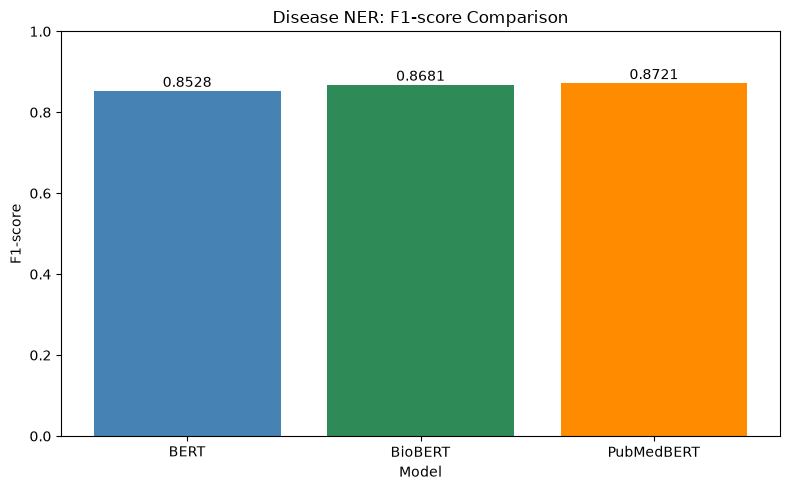

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Model"],
    results_df["F1"],
    color=["steelblue", "seagreen", "darkorange"]
)

plt.title("Disease NER: F1-score Comparison")
plt.xlabel("Model")
plt.ylabel("F1-score")
plt.ylim(0, 1)

for i, score in enumerate(results_df["F1"]):
    plt.text(
        i,
        score + 0.01,
        f"{score:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

### 10.1 Performance Analysis

The experimental results show that both biomedical-domain models outperform the general-domain BERT baseline in terms of F1-score.

- BERT achieves an F1-score of 0.8528.
- BioBERT achieves an F1-score of 0.8681, an improvement of 1.53 percentage points over BERT.
- PubMedBERT achieves the highest F1-score of 0.8721, an improvement of 1.93 percentage points over BERT and 0.40 percentage points over BioBERT.

These results suggest that biomedical-domain pre-training is beneficial for disease named entity recognition.

PubMedBERT's domain-specific vocabulary and biomedical pre-training may contribute to its improved performance. However, the improvement over BioBERT is relatively small.

It should also be noted that BERT and BioBERT results are obtained from the original group experiments, while PubMedBERT is trained on the cleaned dataset in this notebook. Although the data audit confirms that the non-empty samples match, differences in experimental settings may affect the comparison.

Although PubMedBERT achieves the highest F1-score and precision, BioBERT achieves the highest recall and token-level accuracy.

This suggests that BioBERT identifies a larger proportion of annotated disease entities, while PubMedBERT produces more precise disease entity predictions.

PubMedBERT provides the best overall balance between precision and recall, as reflected by its highest F1-score. However, no single model achieves the best performance across all four evaluation metrics.

## 11. Error Analysis

To better understand the strengths and limitations of the best-performing model, we conduct an error analysis of PubMedBERT on the NCBI Disease test set.

We compare the predicted BIO labels with the ground-truth annotations and examine incorrectly classified tokens and disease mentions.

The analysis focuses on:

- Missed disease mentions.
- Incorrectly predicted disease mentions.
- Incorrect disease entity boundaries.

In [33]:
pubmedbert_predictions = pubmedbert_trainer.predict(
    pubmedbert_dataset["test"]
)

predicted_ids = np.argmax(
    pubmedbert_predictions.predictions,
    axis=-1
)

true_ids = pubmedbert_predictions.label_ids

print("Prediction shape:", predicted_ids.shape)
print("Ground truth shape:", true_ids.shape)

/opt/anaconda3/envs/neuralnet/lib/python3.11/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Prediction shape: (940, 130)
Ground truth shape: (940, 130)


In [34]:
error_rows = []

for i in range(len(clean_dataset["test"])):

    words = clean_dataset["test"][i]["tokens"]

    predictions = []
    true_labels = []

    for p, l in zip(predicted_ids[i], true_ids[i]):
        if l != -100:
            predictions.append(id2label[p])
            true_labels.append(id2label[l])

    for j in range(len(true_labels)):
        if predictions[j] != true_labels[j]:

            error_rows.append({
                "Sentence ID": i,
                "Token": words[j],
                "True Label": true_labels[j],
                "Predicted Label": predictions[j],
                "Sentence": " ".join(words)
            })

error_df = pd.DataFrame(error_rows)

print("Total incorrectly classified tokens:", len(error_df))

display(error_df.head(15))

Total incorrectly classified tokens: 353


,Sentence ID,Token,True Label,Predicted Label,Sentence
0,3,T,I-Disease,B-Disease,By analysing tumour DNA from patients with spo...
1,3,T,I-Disease,B-Disease,By analysing tumour DNA from patients with spo...
2,7,A,B-Disease,O,Two of seventeen mutated T - PLL samples had a...
3,7,-,I-Disease,O,Two of seventeen mutated T - PLL samples had a...
4,7,T,I-Disease,O,Two of seventeen mutated T - PLL samples had a...
5,10,mutated,O,B-Disease,The evidence of a significant proportion of lo...
6,10,sporadic,B-Disease,O,The evidence of a significant proportion of lo...
7,10,T,I-Disease,B-Disease,The evidence of a significant proportion of lo...
8,20,isolated,O,B-Disease,Constitutional RB1 - gene mutations in patient...
9,20,unilateral,B-Disease,I-Disease,Constitutional RB1 - gene mutations in patient...


In [35]:
def classify_error(true_label, predicted_label):

    if true_label != "O" and predicted_label == "O":
        return "Missed disease token"

    elif true_label == "O" and predicted_label != "O":
        return "False positive disease token"

    else:
        return "BIO boundary error"


error_df["Error Type"] = error_df.apply(
    lambda row: classify_error(
        row["True Label"],
        row["Predicted Label"]
    ),
    axis=1
)

error_summary = error_df["Error Type"].value_counts()

display(error_summary.to_frame("Count"))

,Count
Error Type,
False positive disease token,172
Missed disease token,118
BIO boundary error,63


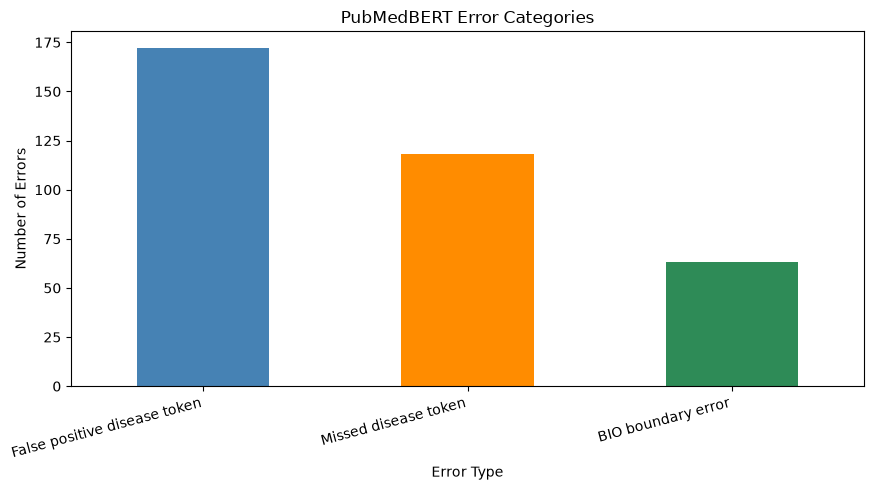

In [36]:
plt.figure(figsize=(9, 5))

error_summary.plot(
    kind="bar",
    color=["steelblue", "darkorange", "seagreen"]
)

plt.title("PubMedBERT Error Categories")
plt.xlabel("Error Type")
plt.ylabel("Number of Errors")
plt.xticks(rotation=15, ha="right")

plt.tight_layout()
plt.show()

### 11.2 Case Study

We examine several representative prediction errors made by PubMedBERT on the test set.

#### Case 1: Missed Disease Tokens

In sentence 10, the token "sporadic" is annotated as B-Disease but predicted as O.

This shows that the model fails to identify the beginning of a disease mention. Such errors may result in incomplete disease entity recognition and reduce recall.

#### Case 2: False Positive Disease Tokens

In sentence 10, the token "mutated" is annotated as O but predicted as B-Disease.

The model incorrectly identifies a biomedical term as part of a disease entity. This suggests that the model may confuse disease-related terminology with actual disease mentions.

#### Case 3: Incorrect Entity Boundaries

In sentences 20, 21, and 23, the model repeatedly predicts "isolated" as B-Disease, although its ground-truth label is O.

At the same time, "unilateral" is annotated as B-Disease but predicted as I-Disease.

These predictions indicate that the model starts the disease entity one token earlier than the ground-truth annotation.

This example demonstrates that the model can identify disease-related expressions but may struggle to determine their exact boundaries.

### 11.3 Error Analysis Summary

PubMedBERT produces 353 token-level prediction errors on the test set.

False positive disease tokens are the most common error type, accounting for 172 errors (48.7%). This indicates that the model sometimes incorrectly classifies non-disease tokens as disease-related tokens.

Missed disease tokens account for 118 errors (33.4%), showing that the model still fails to identify some disease-related words.

BIO boundary errors account for 63 errors (17.8%). These errors indicate difficulties in identifying the exact beginning and continuation of disease entities.

The case studies also reveal that PubMedBERT sometimes includes additional descriptive words in disease mentions, resulting in incorrect entity boundaries.

Overall, although PubMedBERT achieves the highest F1-score among the three baseline models, improving its ability to distinguish disease mentions from surrounding biomedical terminology remains an important challenge.

## 12. Conclusion

In this project, we investigate disease named entity recognition using three pre-trained language models: BERT, BioBERT, and PubMedBERT.

We first conduct a data audit to compare the Hugging Face NCBI Disease dataset with the CoNLL version. The audit identifies one empty sample in each dataset split. After removing these samples, all three splits exactly match the CoNLL dataset.

We then preprocess the dataset using subword tokenization and BIO label alignment, and evaluate the three models using precision, recall, F1-score, and accuracy.

The experimental results show that:

- BERT achieves a test F1-score of 0.8528.
- BioBERT achieves a test F1-score of 0.8681.
- PubMedBERT achieves the highest test F1-score of 0.8721.

Both biomedical-domain models outperform the general-domain BERT baseline. These results suggest that biomedical-domain pre-training can improve disease named entity recognition.

PubMedBERT achieves an improvement of 1.93 percentage points in F1-score over BERT and 0.40 percentage points over BioBERT.

The error analysis shows that false positive disease tokens are the most common prediction errors, followed by missed disease tokens and BIO boundary errors.

Overall, PubMedBERT achieves the best performance in our experiments, although accurate disease entity boundaries and the distinction between disease mentions and other biomedical terminology remain challenging.

### 12.1 Limitations and Future Work

There are several limitations in this project.

First, the BERT and BioBERT results are obtained from the original group experiments, while PubMedBERT is trained on the cleaned dataset in this notebook. Although the data audit confirms that the non-empty samples are identical, differences in experimental settings may affect the comparison.

Second, the experiments do not evaluate performance across multiple random seeds. Therefore, the stability of the reported improvements has not been established.

Third, the error analysis focuses on PubMedBERT. A comparative error analysis across all three models could provide further insights into their strengths and weaknesses.

Future work could include:

- Training all models under identical experimental settings.
- Repeating experiments with multiple random seeds.
- Investigating alternative hyperparameters and training strategies.
- Exploring methods to improve disease entity boundary recognition.
- Evaluating parameter-efficient fine-tuning methods such as LoRA.